# Reconfiguration Test

In [1]:
# Import libraries

import sys
import warnings
from itertools import permutations
from pathlib import Path

import joblib
import pandas as pd
from sklearn.exceptions import InconsistentVersionWarning

In [2]:
GITHUB_ROOT = Path("..")
if not (GITHUB_ROOT / "utils" / "model_conversion.py").is_file():
    raise FileNotFoundError("Run this notebook from its test directory.")
sys.path.insert(0, str(GITHUB_ROOT))
from utils import model_conversion as conversion

if not Path(conversion.__file__).parent.samefile(GITHUB_ROOT / "utils"):
    raise ImportError("Another utils package is cached; restart the kernel and run this notebook first.")

SYSTEMS = {"SS": False, "SS_T": True}
MODELS_DIR = Path("reconfiguration") / "models"
SELECTORS_DIR = MODELS_DIR.parent / "selectors"
if not MODELS_DIR.is_dir():
    raise FileNotFoundError(f"Model directory does not exist: {MODELS_DIR}. Run this notebook from its test directory.")
model_paths = sorted(
    path for path in MODELS_DIR.glob("*.joblib")
    if not path.stem.endswith(("_selector", "_label_encoder"))
)


def load_saved_model(path):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InconsistentVersionWarning)
        return joblib.load(path)


def check_models(paths, system):
    tcam = SYSTEMS[system]
    entry_cache, failures = {}, {}
    for path in paths:
        key = (system, path.stem)
        try:
            model = load_saved_model(path)
            if tcam and isinstance(model, (
                conversion.SVC, conversion.LogisticRegression, conversion.GaussianNB,
                conversion.CategoricalNB, conversion.Perceptron, conversion.KMeans,
            )):
                continue
            selector = load_saved_model(SELECTORS_DIR / f"{path.stem}_selector.joblib")
            label_encoder = (
                None if isinstance(model, conversion.IsolationForest)
                else load_saved_model(path.with_name(f"{path.stem}_label_encoder.joblib"))
            )
        except Exception as error:
            failures[key] = f"Load failed: {type(error).__name__}: {error}"
            continue
        try:
            entries, _ = conversion.convert_model_entries(
                model, {}, tcam, selector=selector, label_encoder=label_encoder,
            )
            entry_cache[key] = entries
        except Exception as error:
            failures[key] = f"Conversion failed: {type(error).__name__}: {error}"
    return entry_cache, failures


def compare_models(paths, entry_cache, failures, system):
    rows = []
    eligible_models = [
        path.stem for path in paths
        if (system, path.stem) in entry_cache or (system, path.stem) in failures
    ]
    for source, destination in permutations(eligible_models, 2):
        keys = [(system, source), (system, destination)]
        reason = "; ".join(f"{key[1]}: {failures[key]}" for key in keys if key in failures)
        if not reason:
            old_entries, new_entries = (entry_cache[key] for key in keys)
            add, mod, delete, _ = conversion.classify_operations(old_entries, new_entries)
            counts = {
                "differential": (len(add), len(mod), len(delete)),
                "delete_then_add": (len(new_entries), 0, len(old_entries)),
            }
        for mode in ("differential", "delete_then_add"):
            add, mod, delete = (pd.NA, pd.NA, pd.NA) if reason else counts[mode]
            rows.append({
                "system": system, "source": source, "destination": destination,
                "mode": mode, "status": "skipped" if reason else "ok",
                "ADD": add, "MOD": mod, "DEL": delete, "reason": reason,
            })
    results = pd.DataFrame(rows, columns=[
        "system", "source", "destination", "mode", "status", "ADD", "MOD", "DEL", "reason",
    ])
    results[["ADD", "MOD", "DEL"]] = results[["ADD", "MOD", "DEL"]].astype("Int64")
    return results


def run_reconfiguration(system):
    entry_cache, failures = check_models(model_paths, system)
    return compare_models(model_paths, entry_cache, failures, system)

In [56]:
ss_results = run_reconfiguration("SS")

In [57]:
ss_t_results = run_reconfiguration("SS_T")

## Baseline reconfiguration counts

ST and IIsy include their supported model families; LEO supports DT only. Baseline ADD/DEL counts use a shared target layout and delete-then-add (MOD = 0). Unsupported transitions and conversion/capacity failures retain missing counts and reasons in `baseline_sram_results` and `baseline_tcam_results`; their bars are omitted. Run this section before plotting. Counting uses only the standalone artifact and writes no generated files.

In [58]:
from utils import baseline_converters as baselines

# Counts use the same quantized feature domain as the SS converter.
# Baselines use delete-then-add; only SS-D uses differential updates.
BASELINE_SYSTEMS = {
    "SRAM": [("ST", "st"), ("IIsy", "iisy"), ("LEO", "leo_sram")],
    "TCAM": [("ST", "st_tcam"), ("IIsy", "iisy_range"), ("LEO", "leo_tcam")],
}
baseline_models, baseline_load_errors = {}, {}
for path in model_paths:
    try:
        baseline_models[path.stem] = load_saved_model(path)
    except Exception as error:
        baseline_load_errors[path.stem] = f"Load failed: {type(error).__name__}: {error}"


def run_baseline_reconfiguration(memory):
    rows = []
    for label, target in BASELINE_SYSTEMS[memory]:
        for source, destination in permutations([path.stem for path in model_paths], 2):
            row = dict(system=label, source=source, destination=destination,
                       mode="delete_then_add", status="ok", reason="")
            try:
                errors = [baseline_load_errors[name] for name in (source, destination)
                          if name in baseline_load_errors]
                if errors:
                    raise ValueError("; ".join(errors))
                row.update(baselines.count_reconfiguration_operations(
                    baseline_models[source], baseline_models[destination], target,
                ))
            except baselines.UnsupportedTransitionError as error:
                row.update(status="unsupported", reason=str(error))
            except Exception as error:
                row.update(status="failed", reason=f"{type(error).__name__}: {error}")
            rows.append(row)
    frame = pd.DataFrame(rows, columns=ss_results.columns)
    frame[["ADD", "MOD", "DEL"]] = frame[["ADD", "MOD", "DEL"]].astype("Int64")
    return frame


baseline_sram_results = run_baseline_reconfiguration("SRAM")
baseline_tcam_results = run_baseline_reconfiguration("TCAM")

# Plotting

In [59]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import ScalarFormatter
import numpy as np

COMPARE_TRANSITIONS = [
    ("DT1", "RF1"), ("DT1", "RF2"), ("DT1", "IF1"), ("DT1", "XGB2"),
    ("DT2", "RF1"), ("DT2", "XGB1"), ("RF1", "IF2"), ("RF2", "XGB2"),
    ("IF1", "XGB1"), ("KM1", "NB1"),
]
EXCLUSIVE_TRANSITIONS = [
    ("DT1", "SVM1"), ("DT2", "SVM2"), ("RF1", "LR1"), ("XGB1", "KM1"),
    ("IF1", "NB1"), ("SVM1", "DT1"), ("SLP2", "RF2"), ("LR1", "SVM1"),
    ("NB2", "SLP1"),
]


def select_tcam_transitions(transitions):
    supported_models = ("DT", "RF", "XGB", "IF")
    return [pair for pair in transitions
            if all(model.startswith(supported_models) for model in pair)]


def plot_operation_counts(results, transitions, system, title, baseline_results=None):
    if set(results["system"]) != {system}:
        raise ValueError(f"Expected results for {system} only")
    indexed = results.set_index(["source", "destination", "mode"])
    if not indexed.index.is_unique:
        raise ValueError("Duplicate comparison rows")
    modes = [("delete_then_add", "SS", ".."), ("differential", "SS-D", "//")]
    operations = ["ADD", "MOD", "DEL"]
    colors = ["#F7F7F7", "#4C78A8", "#D9D9D9"]
    counts = []
    for mode, _, _ in modes:
        values = []
        for source, destination in transitions:
            key = (source.lower(), destination.lower(), mode)
            if key not in indexed.index:
                raise ValueError(f"Missing {system} comparison: {source} -> {destination} ({mode})")
            row = indexed.loc[key]
            if row["status"] != "ok" or row[operations].isna().any():
                raise ValueError(f"Unavailable {system} comparison: {source} -> {destination}: {row['reason']}")
            values.append([int(row[operation]) for operation in operations])
        counts.append(values)
    if baseline_results is not None:
        baseline_indexed = baseline_results.set_index(["system", "source", "destination"])
        if not baseline_indexed.index.is_unique:
            raise ValueError("Duplicate baseline comparison rows")
        baseline_counts = []
        baseline_modes = [("delete_then_add", "ST", ""), ("delete_then_add", "IIsy", "\\\\"),
                          ("delete_then_add", "LEO", "xx")]
        for _, label, _ in baseline_modes:
            keys = [(label, source.lower(), destination.lower())
                    for source, destination in transitions]
            selected = baseline_indexed.reindex(keys)
            valid = selected["status"].eq("ok") & selected[operations].notna().all(axis=1)
            values = selected[operations].where(valid, axis=0)
            baseline_counts.append(values.to_numpy(dtype=float, na_value=np.nan))
        counts = baseline_counts + counts
        modes = baseline_modes + modes
    counts = np.asarray(counts)
    if not transitions or np.any(counts < 0):
        raise ValueError("Plotting requires transitions with nonnegative operation counts")

    with plt.rc_context({"font.family": "Times New Roman", "font.size": 20}):
        fig, ax = plt.subplots(figsize=(24, 8))
        x = np.arange(len(transitions))
        visible = np.isfinite(counts).all(axis=2)
        bar_width = 0.8 / visible.sum(axis=0).max()
        offsets = (visible.cumsum(axis=0) - (visible.sum(axis=0) + 1) / 2) * bar_width
        for mode_index, (_, _, hatch) in enumerate(modes):
            mask = visible[mode_index]
            positions = x[mask] + offsets[mode_index, mask]
            bottom = np.zeros(mask.sum())
            for operation_index, color in enumerate(colors):
                heights = counts[mode_index, mask, operation_index]
                ax.bar(positions, heights, width=bar_width * 0.9, bottom=bottom,
                       color=color, edgecolor="black", linewidth=0.8, hatch=hatch)
                bottom += heights
        ax.set_xticks(x)
        ax.set_xticklabels([f"{source}->{destination}" for source, destination in transitions],
                           rotation=25, ha="right")
        ax.set_ylabel("# Ops")
        ax.set_title(title)
        ax.set_ylim(0, max(1, np.nansum(counts, axis=2).max() * 1.15))
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.25)
        formatter = ScalarFormatter(useMathText=False)
        formatter.set_scientific(True)
        formatter.set_powerlimits((3, 3))
        ax.yaxis.set_major_formatter(formatter)
        handles = [Patch(facecolor=color, edgecolor="black", label=operation)
                   for operation, color in zip(operations, colors)]
        handles += [Patch(facecolor="white", edgecolor="black", hatch=hatch, label=label)
                    for index, (_, label, hatch) in enumerate(modes) if visible[index].any()]
        fig.legend(handles=handles, loc="upper center", ncol=len(handles), fontsize=16)
        fig.tight_layout(rect=(0, 0, 1, 0.91))
    return fig

# Figure 10(a) and Figure 10(b)

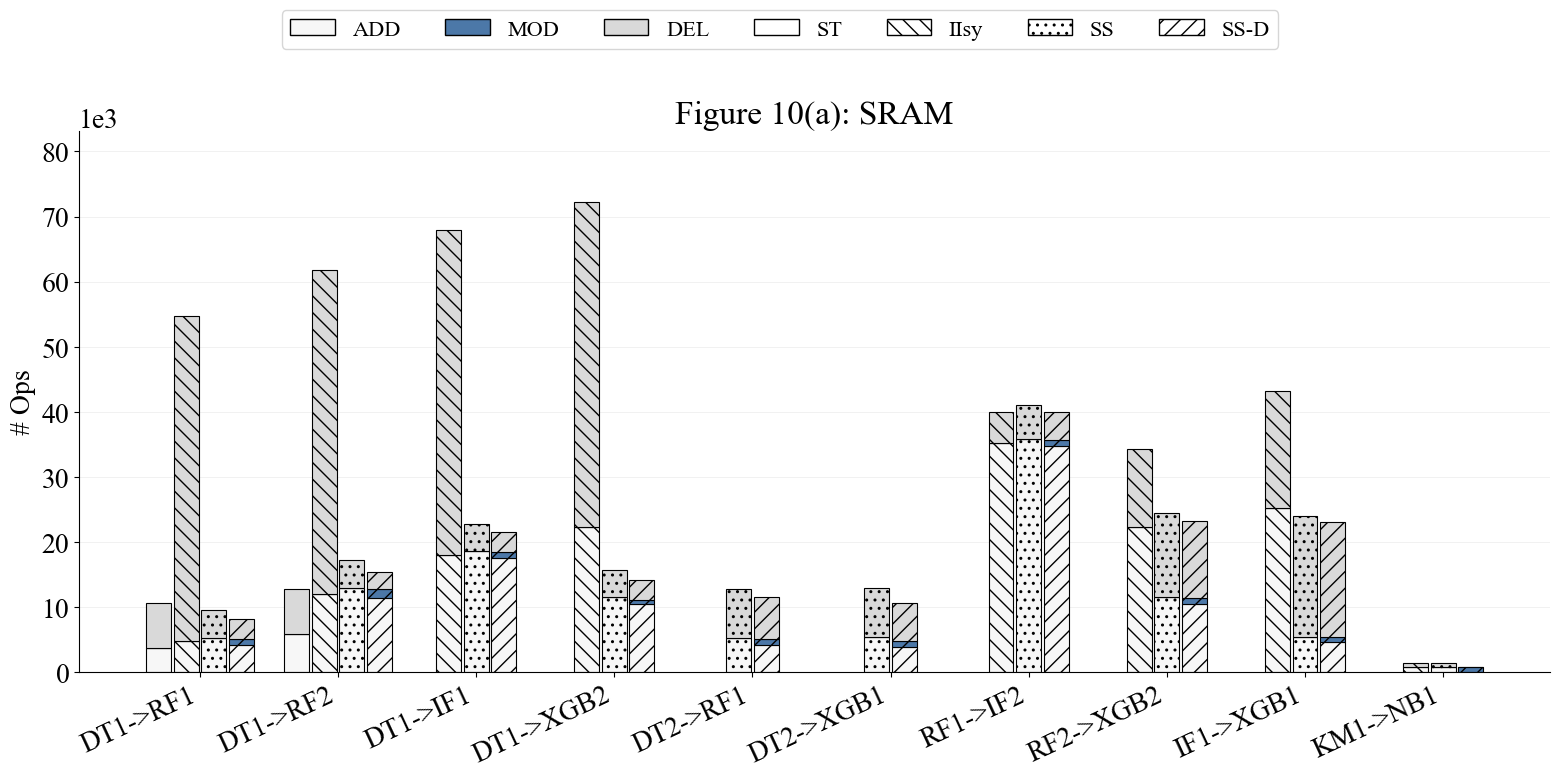

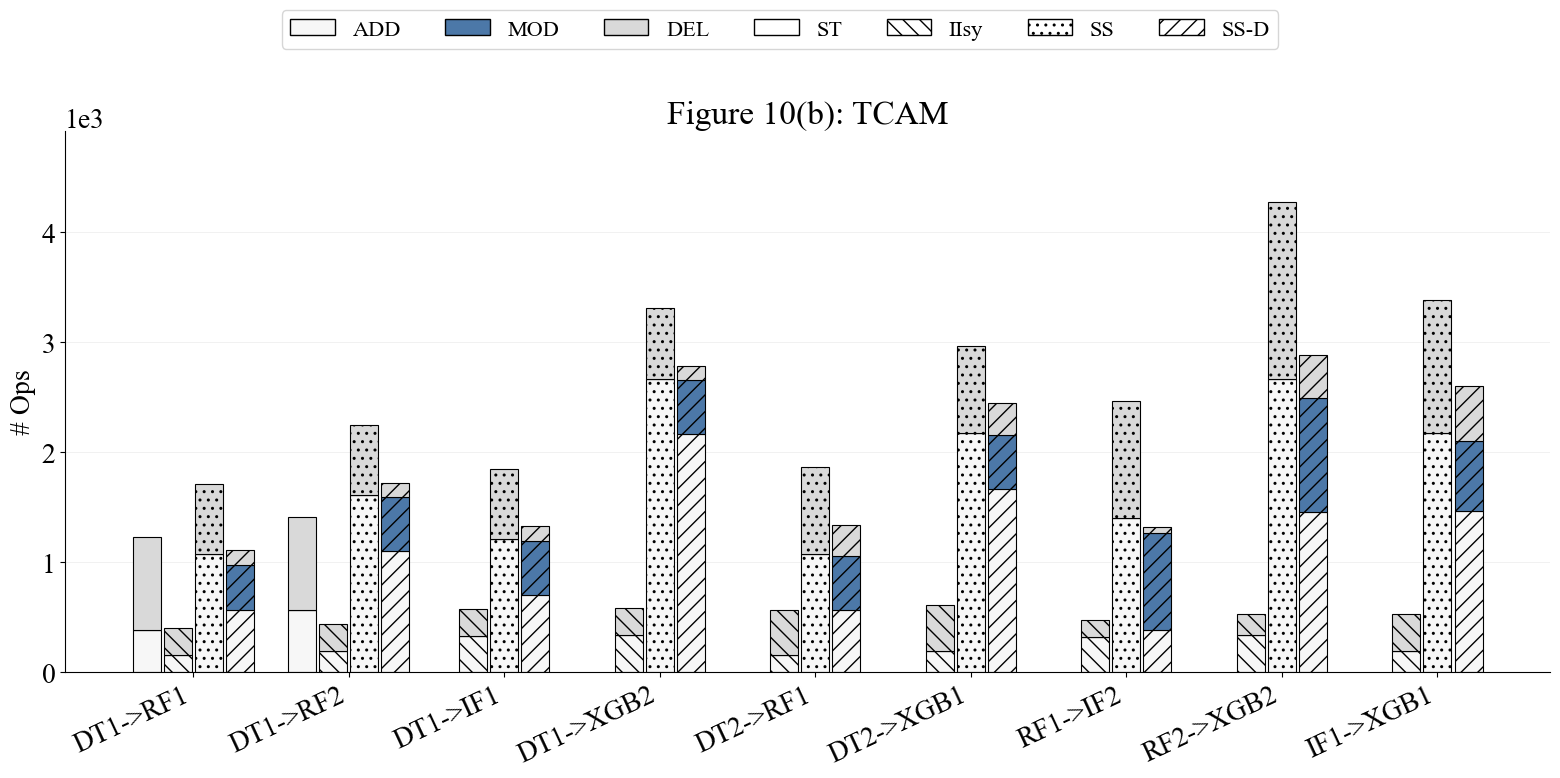

In [60]:
fig_10a = plot_operation_counts(
    ss_results, COMPARE_TRANSITIONS, "SS", "Figure 10(a): SRAM",
    baseline_results=baseline_sram_results,
)
plt.show()

tcam_transitions = select_tcam_transitions(COMPARE_TRANSITIONS)
fig_10b = plot_operation_counts(
    ss_t_results, tcam_transitions, "SS_T", "Figure 10(b): TCAM",
    baseline_results=baseline_tcam_results,
)
plt.show()

# Figure 11

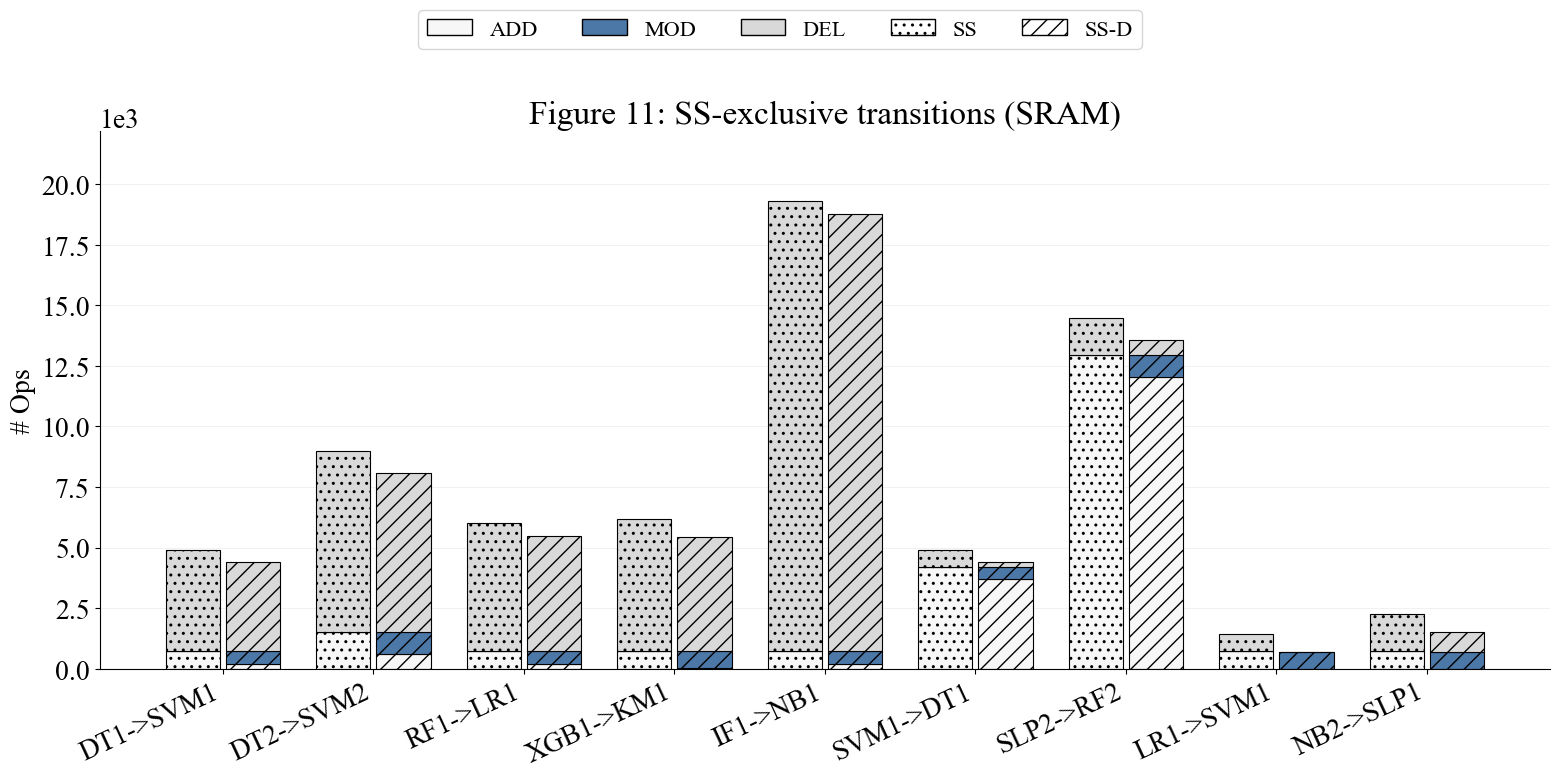

In [61]:
fig_11 = plot_operation_counts(
    ss_results, EXCLUSIVE_TRANSITIONS, "SS", "Figure 11: SS-exclusive transitions (SRAM)",
    baseline_results=baseline_sram_results,
)
plt.show()

# Figure 18(a) and Figure 18(b)

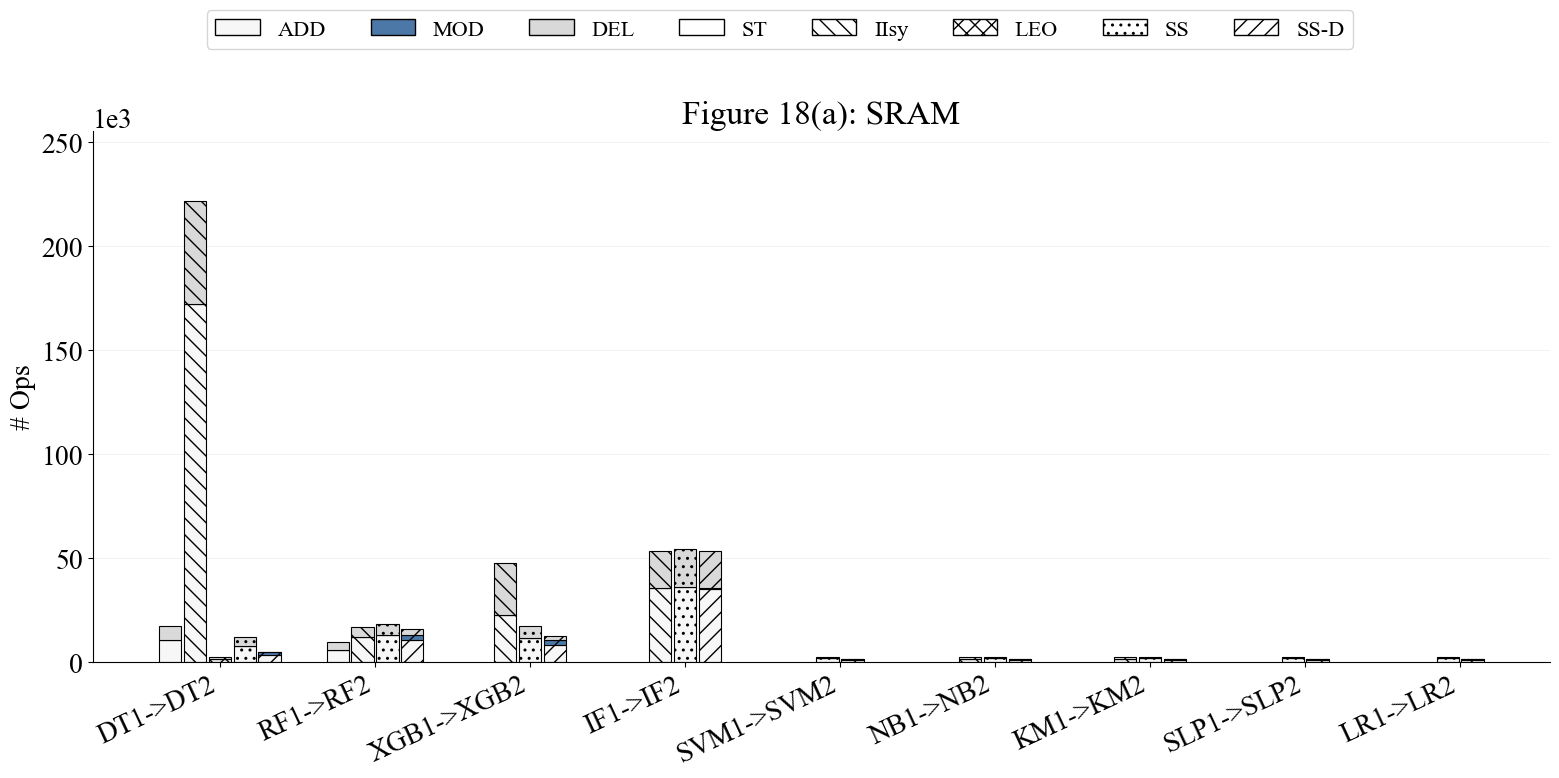

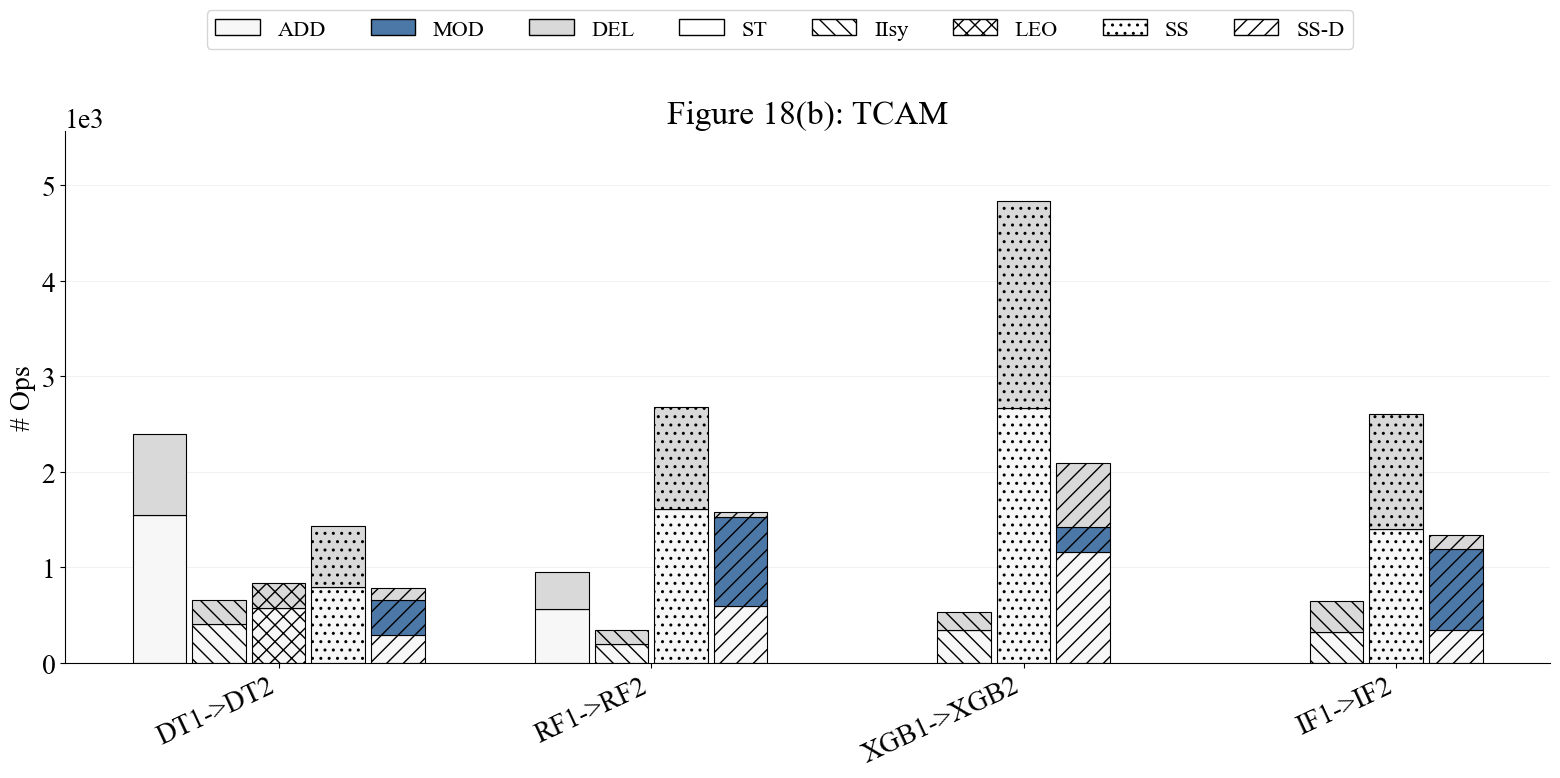

In [62]:
INTRA_TRANSITIONS = [
    ("DT1", "DT2"), ("RF1", "RF2"), ("XGB1", "XGB2"), ("IF1", "IF2"),
    ("SVM1", "SVM2"), ("NB1", "NB2"), ("KM1", "KM2"), ("SLP1", "SLP2"),
    ("LR1", "LR2"),
]

fig_18a = plot_operation_counts(
    ss_results, INTRA_TRANSITIONS, "SS", "Figure 18(a): SRAM",
    baseline_results=baseline_sram_results,
)
plt.show()

intra_tcam_transitions = select_tcam_transitions(INTRA_TRANSITIONS)
fig_18b = plot_operation_counts(
    ss_t_results, intra_tcam_transitions, "SS_T", "Figure 18(b): TCAM",
    baseline_results=baseline_tcam_results,
)
plt.show()

# Figure 19(a) and Figure 19(b)

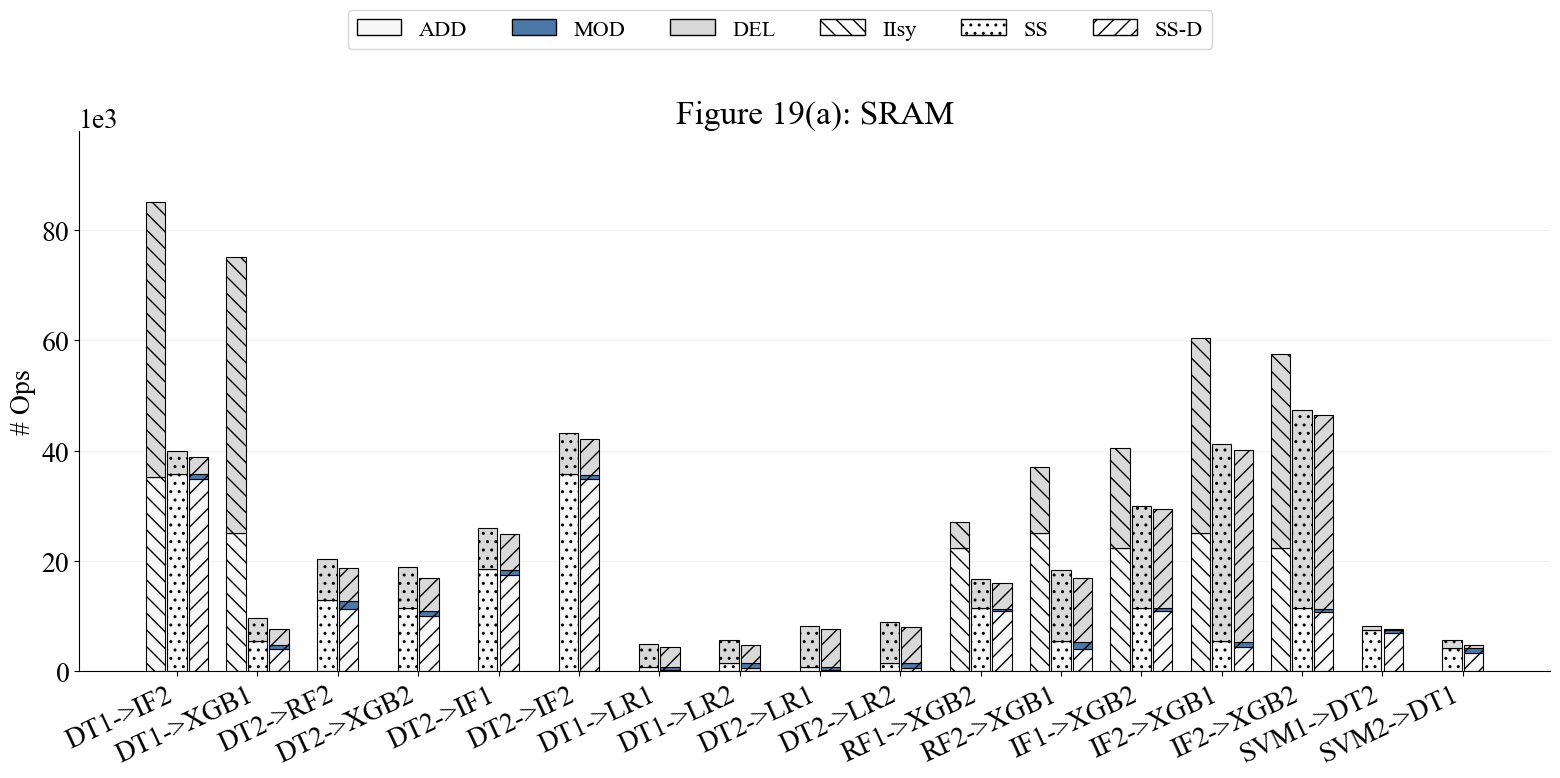

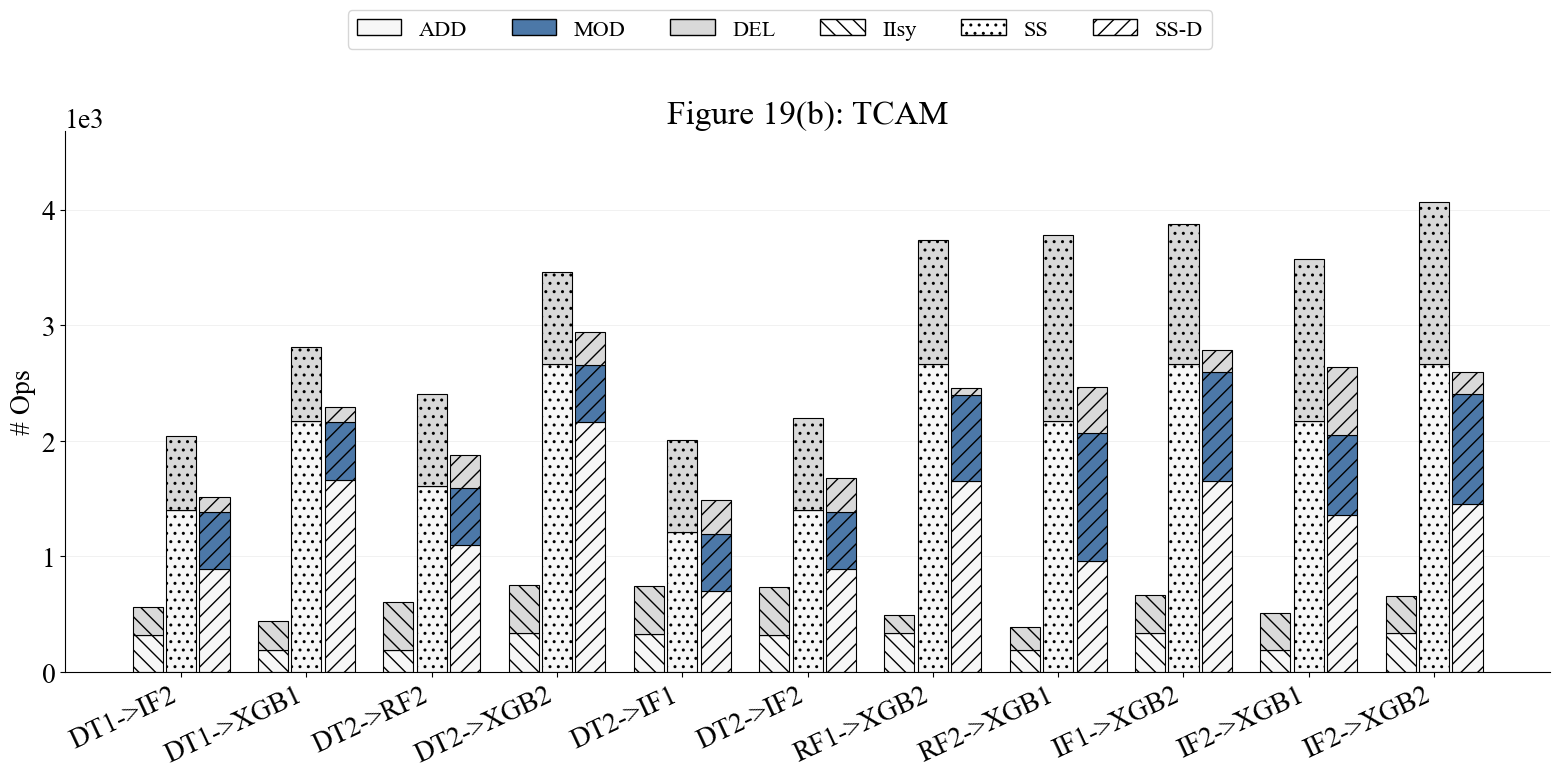

In [63]:
OTHER_TRANSITIONS = [
    ("DT1", "IF2"), ("DT1", "XGB1"), ("DT2", "RF2"), ("DT2", "XGB2"),
    ("DT2", "IF1"), ("DT2", "IF2"), ("DT1", "LR1"), ("DT1", "LR2"),
    ("DT2", "LR1"), ("DT2", "LR2"), ("RF1", "XGB2"), ("RF2", "XGB1"),
    ("IF1", "XGB2"), ("IF2", "XGB1"), ("IF2", "XGB2"),
    ("SVM1", "DT2"), ("SVM2", "DT1"),
]

fig_19a = plot_operation_counts(
    ss_results, OTHER_TRANSITIONS, "SS", "Figure 19(a): SRAM",
    baseline_results=baseline_sram_results,
)
plt.show()

other_tcam_transitions = select_tcam_transitions(OTHER_TRANSITIONS)
fig_19b = plot_operation_counts(
    ss_t_results, other_tcam_transitions, "SS_T", "Figure 19(b): TCAM",
    baseline_results=baseline_tcam_results,
)
plt.show()